# Chapter 1 — The Machine Learning Landscape
## Does Money Make People Happier? (OECD Life Satisfaction vs. GDP per Capita)

This notebook follows the first practical project in the textbook:
1. **Setup & Imports**: Import data science and machine learning libraries.
2. **Load Raw Data**: Load the OECD Better Life Index and World Bank GDP per capita datasets.
3. **Explore Raw Tables**: Inspect table structures, columns, and shapes.
4. **Data Preparation Pipeline**: Filter, pivot, merge, and clean the data into a unified table (`prepare_country_stats`).
5. **Visualize the Relationship**: Scatter plot of GDP per capita versus Life Satisfaction.
6. **Train a Model-Based Algorithm**: Fit a `LinearRegression` model.
7. **Visualize the Decision Boundary**: Plot the learned best-fit trend line.
8. **Make Predictions on New Data**: Predict life satisfaction for new, unseen countries.
9. **Model-Based vs. Instance-Based Learning**: Compare `LinearRegression` against `KNeighborsRegressor`.

> **Quick Vocabulary Review:**
> - **DataFrame**: A 2D labeled table (rows + columns) provided by pandas.
> - **Series**: A single column of a DataFrame.
> - **`.head()`**: Previews the first 5 rows without modifying the underlying data.
> - **`NaN`**: "Not a Number" representing missing values.

---
## 1. Environment Setup & Imports

Import the core Python libraries:
- `matplotlib.pyplot`: Plotting and data visualization.
- `numpy`: Fast multidimensional numerical arrays.
- `pandas`: Data loading, cleaning, filtering, and merging.
- `seaborn`: Statistical plot styling.
- `sklearn.linear_model.LinearRegression`: Linear regression model from Scikit-Learn.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

print(f"NumPy version:  {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print("Ready!")

NumPy version:  2.5.4
Pandas version: 3.0.6
Ready!


---
## 2. Load the Raw Datasets

We load two separate data sources located in `../data/`:
1. **OECD Better Life Index (`oecd_bli.csv`)**: Life satisfaction survey ratings across OECD countries.
   - `thousands=","`: Parses comma-formatted numbers (e.g. `"1,234"`) as numeric values.
2. **World Bank GDP per Capita (`gdp_per_capita.csv`)**: Gross Domestic Product per person in US dollars.
   - `encoding="latin1"`: Handles special international character encodings.
   - `na_values="n/a"`: Maps `"n/a"` text tokens to true `NaN` values.
   - `skiprows=4`: Skips metadata header comments so row 5 becomes the column headers.

In [2]:
oecd_bli = pd.read_csv(
    "../data/oecd_bli.csv",
    thousands=",",
)

gdp_per_capita = pd.read_csv(
    "../data/gdp_per_capita.csv",
    thousands=",",
    encoding="latin1",
    na_values="n/a",
    skiprows=4,
)

---
## 3. Explore the Raw Tables

Before merging, let's inspect the structure, columns, and sample records of both raw tables.

### 3.1 Inspecting the OECD Better Life Index
Notice this table is in **long format** (multiple indicator rows per country).

In [3]:
print(f"OECD shape: {oecd_bli.shape} (rows, columns)")
oecd_bli.head()

OECD shape: (2369, 22) (rows, columns)


,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,ACTION,LOCATION,Country,INDICATOR,Indicator,MEASURE,Measure,...,OBS_VALUE,Observation Value,OBS_STATUS,Observation Status,UNIT_MEASURE,Unit of Measures,UNIT_MULT,Multiplier,BASE_PER,Base reference period
0,DATAFLOW,OECD:DF_BLI(1.0),Better Life Index,I,AUT,Austria,JE_LMIS,Labour market insecurity,L,Value,...,2.3,NaN,A,NaN,PC,Percentage,0,Units,NaN,NaN
1,DATAFLOW,OECD:DF_BLI(1.0),Better Life Index,I,BEL,Belgium,JE_LMIS,Labour market insecurity,L,Value,...,2.4,NaN,A,NaN,PC,Percentage,0,Units,NaN,NaN
2,DATAFLOW,OECD:DF_BLI(1.0),Better Life Index,I,CAN,Canada,JE_LMIS,Labour market insecurity,L,Value,...,3.8,NaN,A,NaN,PC,Percentage,0,Units,NaN,NaN
3,DATAFLOW,OECD:DF_BLI(1.0),Better Life Index,I,CZE,Czechia,JE_LMIS,Labour market insecurity,L,Value,...,2.3,NaN,A,NaN,PC,Percentage,0,Units,NaN,NaN
4,DATAFLOW,OECD:DF_BLI(1.0),Better Life Index,I,DNK,Denmark,JE_LMIS,Labour market insecurity,L,Value,...,4.5,NaN,A,NaN,PC,Percentage,0,Units,NaN,NaN


### 3.2 Inspecting the World Bank GDP Table
Notice this table is in **wide format** (each year from 1960 to the latest year has its own column).

In [4]:
print(f"GDP shape:  {gdp_per_capita.shape} (rows, columns)")
gdp_per_capita.head()

GDP shape:  (266, 71) (rows, columns)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,28440.041688,30082.158423,30654.485124,22664.370995,26827.344787,31000.571380,34897.618393,38590.565029,NaN,NaN
1,Africa Eastern and Southern,AFE,GDP per capita (current US$),NY.GDP.PCAP.CD,186.089515,186.909365,197.367876,225.400456,208.963066,226.836513,...,1529.923080,1553.617944,1508.031525,1351.503167,1560.894626,1675.902524,1571.132704,1628.227289,1722.385620,NaN
2,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,525.469771,491.337221,496.602504,510.787063,356.496214,357.261153,413.757895,416.871146,NaN,NaN
3,Africa Western and Central,AFW,GDP per capita (current US$),NY.GDP.PCAP.CD,121.936832,127.451040,133.823783,139.004980,148.551510,155.587905,...,1577.203497,1723.114463,2219.412555,2034.437940,2116.938294,2143.072094,1846.246811,1416.228412,1600.058374,NaN
4,Angola,AGO,GDP per capita (current US$),NY.GDP.PCAP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,2832.149980,2891.830324,2507.868072,1749.179484,2266.968349,3598.536691,2885.513491,2720.819007,3129.476623,NaN


---
## 4. Data Preparation Pipeline (`prepare_country_stats`)

To train a model, we need a single clean table containing `Country`, `GDP per capita`, and `Life satisfaction`:
1. **Filter Total Inequality**: `Inequality == "Total"` keeps overall country scores rather than gender/age demographic breakdowns.
2. **Pivot Long to Wide**: `pivot(index="Country", columns="Indicator", values="OBS_VALUE")` creates one row per country, turning indicators into columns.
3. **Rename & Index GDP**: Standardize `Country Name` to `Country` and select the latest representative year (e.g. `2023`) as `GDP per capita`.
4. **Merge on Country**: Inner-join both tables on matching country index labels.
5. **Drop Missing Data**: Remove countries missing either GDP or life satisfaction.

In [5]:
def prepare_country_stats(oecd_bli, gdp_per_capita):
    # 1. Filter for total population scores
    oecd = oecd_bli[oecd_bli["Inequality"] == "Total"].copy()

    # 2. Reshape long format to wide format (indicators become columns)
    oecd = oecd.pivot(index="Country", columns="Indicator", values="OBS_VALUE")

    # 3. Standardize column names and index for GDP
    gdp = gdp_per_capita.rename(
        columns={"Country Name": "Country", "2023": "GDP per capita"}
    )
    gdp = gdp.set_index("Country")

    # 4. Merge tables on Country index
    full = pd.merge(
        left=oecd,
        right=gdp[["GDP per capita"]],
        left_index=True,
        right_index=True,
    )

    # 5. Clean missing values and select our target attributes
    full = full.dropna(subset=["GDP per capita", "Life satisfaction"])
    return full[["GDP per capita", "Life satisfaction"]].sort_values("GDP per capita")

### Clean Training Table
Let's run the pipeline and preview the resulting dataset (sorted from poorest to richest).

In [6]:
country_stats = prepare_country_stats(oecd_bli, gdp_per_capita)
print(f"Total countries available for training: {len(country_stats)}")
country_stats.head(10)

Total countries available for training: 38


,GDP per capita,Life satisfaction
Country,,
South Africa,6034.272090,4.9
Colombia,7012.491691,5.7
Brazil,10377.589279,6.1
Mexico,13830.843849,6.0
Chile,17081.518074,6.2
Costa Rica,17140.771430,6.3
Poland,22145.266065,6.1
Hungary,22208.650982,6.0
Latvia,22710.263754,6.2


---
## 5. Visualize the Relationship

Plot a scatter plot of **GDP per capita** ($x$-axis) versus **Life satisfaction** ($y$-axis).

There is an apparent positive trend: as GDP per capita increases, reported life satisfaction generally rises as well.

<Figure size 1000x600 with 0 Axes>

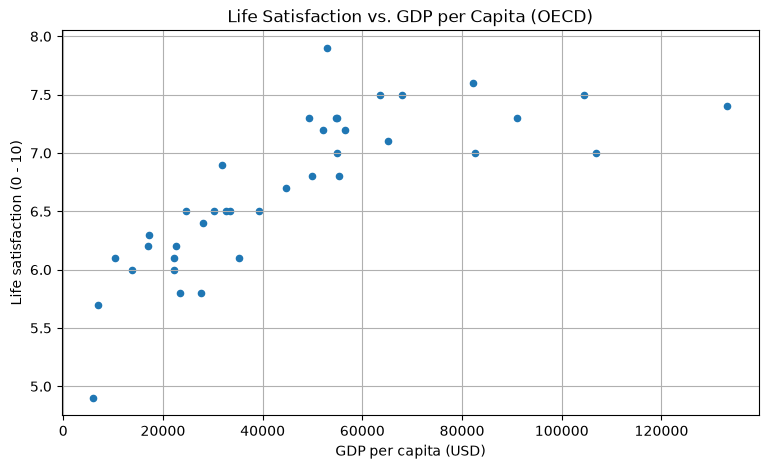

In [7]:
plt.figure(figsize=(10, 6))
country_stats.plot(
    kind="scatter",
    x="GDP per capita",
    y="Life satisfaction",
    figsize=(9, 5),
    grid=True,
)
plt.title("Life Satisfaction vs. GDP per Capita (OECD)")
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction (0 - 10)")
plt.show()

---
## 6. Train a Model-Based Algorithm (Linear Regression)

In **model-based learning**, the system learns parameters of a general mathematical formula:

$$\text{Life satisfaction} = \theta_0 + \theta_1 \times \text{GDP per capita}$$

- $\theta_0$ (`intercept_`): The baseline satisfaction when GDP is 0.
- $\theta_1$ (`coef_`): The slope (how much satisfaction changes per dollar increase in GDP).

Scikit-Learn expects the input feature matrix $X$ to be a 2D array of shape `(n_samples, n_features)` and $y$ as a 2D array or 1D vector.

In [8]:
# Prepare feature matrix X (2D) and target vector y (2D)
X = np.c_[country_stats["GDP per capita"]]
y = np.c_[country_stats["Life satisfaction"]]

# Select a linear model and train (fit) on the data
model = LinearRegression()
model.fit(X, y)

theta_0 = model.intercept_[0]
theta_1 = model.coef_[0][0]

print(f"Model parameters learned from {len(country_stats)} countries:")
print(f"  Intercept (theta_0): {theta_0:.4f}")
print(f"  Slope     (theta_1): {theta_1:.8f}")
print(f"\nModel equation: Life_sat = {theta_0:.4f} + {theta_1:.8f} * GDP")

Model parameters learned from 38 countries:
  Intercept (theta_0): 5.9027
  Slope     (theta_1): 0.00001703

Model equation: Life_sat = 5.9027 + 0.00001703 * GDP


---
## 7. Visualize the Learned Model

Plot the learned regression line $\hat{y} = \theta_0 + \theta_1 x$ directly over the training data points to see how well it fits the distribution.

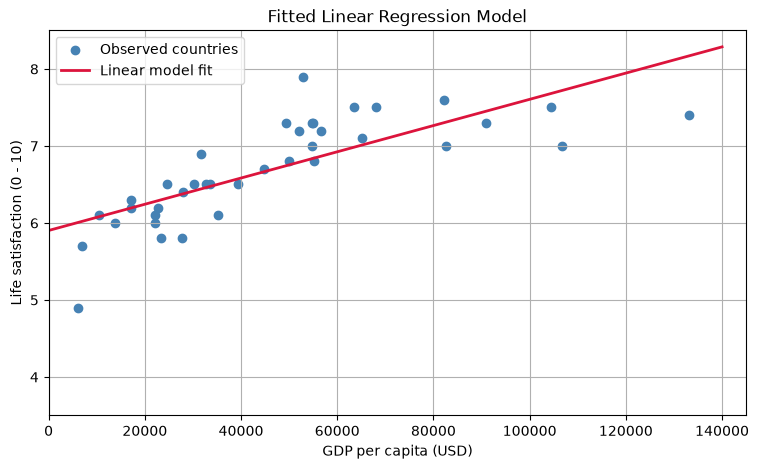

In [9]:
plt.figure(figsize=(9, 5))
plt.scatter(country_stats["GDP per capita"], country_stats["Life satisfaction"], color="steelblue", label="Observed countries")

# Generate line coordinates across the GDP range
x_vals = np.linspace(0, 140000, 1000).reshape(-1, 1)
y_vals = model.predict(x_vals)
plt.plot(x_vals, y_vals, color="crimson", linewidth=2, label="Linear model fit")

plt.title("Fitted Linear Regression Model")
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction (0 - 10)")
plt.xlim(0, 145000)
plt.ylim(3.5, 8.5)
plt.grid(True)
plt.legend()
plt.show()

---
## 8. Making Predictions for New Countries

To predict life satisfaction for a country not in the training set, provide its GDP per capita to `model.predict()`.

> **Input Shape:** The input must have shape `(n_samples, n_features)`, such as `[[gdp_value]]`.

In [10]:
# Predict for Egypt (e.g. GDP ~ $4,000 USD)
gdp_egypt = [[4000.0]]
predicted_egypt = model.predict(gdp_egypt)[0][0]
print(f"Predicted life satisfaction for Egypt (GDP ${gdp_egypt[0][0]:,.0f}): {predicted_egypt:.2f}")

# Predict for a mid-income country (e.g. Cyprus ~ $37,655 USD)
gdp_cyprus = [[37655.0]]
predicted_cyprus = model.predict(gdp_cyprus)[0][0]
print(f"Predicted life satisfaction for Cyprus (GDP ${gdp_cyprus[0][0]:,.0f}): {predicted_cyprus:.2f}")

Predicted life satisfaction for Egypt (GDP $4,000): 5.97
Predicted life satisfaction for Cyprus (GDP $37,655): 6.54


---
## 9. Model-Based vs. Instance-Based Learning

As discussed in the Chapter 1 notes, there are two distinct learning paradigms:
- **Model-Based (`LinearRegression`)**: Generalizes by estimating fixed global parameters (slope & intercept). Fast inference, but cannot capture complex non-linear curves without extra feature engineering.
- **Instance-Based (`KNeighborsRegressor`)**: Memorizes the training instances. To predict for a new country, it finds the $k$ most similar countries (closest GDP per capita) and averages their life satisfaction scores.

Let's test $k$-Nearest Neighbors ($k=3$) on the same data:
```python
from sklearn.neighbors import KNeighborsRegressor
knn_model = KNeighborsRegressor(n_neighbors=3)
knn_model.fit(X, y)
```

In [11]:
from sklearn.neighbors import KNeighborsRegressor

knn_model = KNeighborsRegressor(n_neighbors=3)
knn_model.fit(X, y)

knn_egypt = knn_model.predict(gdp_egypt)[0][0]
knn_cyprus = knn_model.predict(gdp_cyprus)[0][0]

print("Comparison of Predictions:")
print(f"  Egypt  (GDP ${gdp_egypt[0][0]:,.0f}):")
print(f"    Linear Regression: {predicted_egypt:.2f}")
print(f"    k-NN (k=3):        {knn_egypt:.2f}")
print(f"  Cyprus (GDP ${gdp_cyprus[0][0]:,.0f}):")
print(f"    Linear Regression: {predicted_cyprus:.2f}")
print(f"    k-NN (k=3):        {knn_cyprus:.2f}")

Comparison of Predictions:
  Egypt  (GDP $4,000):
    Linear Regression: 5.97
    k-NN (k=3):        5.57
  Cyprus (GDP $37,655):
    Linear Regression: 6.54
    k-NN (k=3):        6.37
